# **JOBSHEET 5: TEKNIK SEGMENTASI GAMBAR**


---


> Khumaira Yuliazzara (3.34.24.9.04)

## Persiapan Lingkungan

In [ ]:
%pip install -q transformers

In [ ]:
import os, time, random, json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(42)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CEPAT = DEVICE == "cpu"
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Perangkat:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU saja")

CFG = dict(
    IMG = 128 if CEPAT else 256,
    N_TRAIN = 320 if CEPAT else 2000,
    N_TEST = 100 if CEPAT else 500,
    BATCH = 16,
    EP_UNET = 6 if CEPAT else 15,
    EP_DLV3 = 2 if CEPAT else 6,
    EP_SEGF = 3 if CEPAT else 6,
    BASE_CH = 16 if CEPAT else 32,
)
print("Mode:", "CEPAT (CPU)" if CEPAT else "PENUH (GPU)", CFG)
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
WAKTU = {}

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
Perangkat: cuda | Tesla T4
Mode: PENUH (GPU) {'IMG': 256, 'N_TRAIN': 2000, 'N_TEST': 500, 'BATCH': 16, 'EP_UNET': 15, 'EP_DLV3': 6, 'EP_SEGF': 6, 'BASE_CH': 32}


## Praktikum D1: Mengenal Data Segmentasi (Oxford-IIIT Pet)

In [ ]:
import tarfile, urllib.request

URL_IMG = "https://thor.robots.ox.ac.uk/pets/images.tar.gz"
URL_ANN = "https://thor.robots.ox.ac.uk/pets/annotations.tar.gz"

def ambil_subset_pet(root="data/pet_subset", n_train=480, n_test=120):
    os.makedirs(f"{root}/images", exist_ok=True); os.makedirs(f"{root}/trimaps", exist_ok=True)
    ann = f"{root}/annotations.tar.gz"
    if not os.path.exists(ann):
        urllib.request.urlretrieve(URL_ANN, ann)
    split, trimaps = {}, {}
    with tarfile.open(ann, "r:gz") as t:
        for m in t:
            if m.name.endswith("annotations/trainval.txt") or m.name.endswith("annotations/test.txt"):
                s = "train" if "trainval" in m.name else "test"
                for line in t.extractfile(m).read().decode().splitlines():
                    if line.strip():
                        split[line.split()[0]] = s
            elif "/trimaps/" in m.name and m.name.endswith(".png") and "._" not in m.name:
                trimaps[os.path.basename(m.name)[:-4]] = t.extractfile(m).read()

    def hitung():
        ada = [f[:-4] for f in os.listdir(f"{root}/images") if f.endswith(".jpg")]
        return (sorted(i for i in ada if split.get(i) == "train"),
                sorted(i for i in ada if split.get(i) == "test"))

    tr, te = hitung()
    if len(tr) >= n_train and len(te) >= n_test:
        print("Subset sudah tersedia di", root)
        return tr[:n_train], te[:n_test]
    with urllib.request.urlopen(URL_IMG) as resp, tarfile.open(fileobj=resp, mode="r|gz") as t:
        for m in t:
            nama = os.path.basename(m.name)
            if not nama.endswith(".jpg"):
                continue
            iid = nama[:-4]; s = split.get(iid)
            if iid not in trimaps or s is None:
                continue
            if (s == "train" and len(tr) >= n_train) or (s == "test" and len(te) >= n_test):
                continue
            with open(f"{root}/images/{nama}", "wb") as f: f.write(t.extractfile(m).read())
            with open(f"{root}/trimaps/{iid}.png", "wb") as f: f.write(trimaps[iid])
            (tr if s == "train" else te).append(iid)
            if len(tr) >= n_train and len(te) >= n_test:
                break
    tr, te = hitung()
    return tr[:n_train], te[:n_test]

t0 = time.time()
ROOT = "data/pet_subset"
ID_TRAIN, ID_TEST = ambil_subset_pet(ROOT, CFG["N_TRAIN"], CFG["N_TEST"])
print(f"Citra latih: {len(ID_TRAIN)} | citra uji: {len(ID_TEST)} | waktu {time.time()-t0:.1f} detik")
print("Jumlah ras pada data latih:", len({i.rsplit('_', 1)[0] for i in ID_TRAIN}))

Subset sudah tersedia di data/pet_subset
Citra latih: 2000 | citra uji: 500 | waktu 0.8 detik
Jumlah ras pada data latih: 37


In [ ]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def muat_pasangan(iid, size):
    img = Image.open(f"{ROOT}/images/{iid}.jpg").convert("RGB").resize((size, size), Image.BILINEAR)
    tri = Image.open(f"{ROOT}/trimaps/{iid}.png").resize((size, size), Image.NEAREST)
    return np.array(img), np.array(tri)

class PetSegDataset(torch.utils.data.Dataset):
    def __init__(self, ids, size, augment=False):
        pairs = [muat_pasangan(i, size) for i in ids]
        self.img = torch.from_numpy(np.stack([p[0] for p in pairs])).permute(0, 3, 1, 2)
        self.tri = torch.from_numpy(np.stack([p[1] for p in pairs]))
        self.augment = augment
    def __len__(self):
        return len(self.img)
    def __getitem__(self, i):
        x = self.img[i].float() / 255.0
        tri = self.tri[i]
        y = (tri == 1).float().unsqueeze(0)
        valid = (tri != 3).float().unsqueeze(0)
        if self.augment and random.random() < 0.5:
            x, y, valid = x.flip(-1), y.flip(-1), valid.flip(-1)
        return (x - MEAN) / STD, y, valid

t0 = time.time()
ds_train = PetSegDataset(ID_TRAIN, CFG["IMG"], augment=True)
ds_test = PetSegDataset(ID_TEST, CFG["IMG"], augment=False)
dl_train = torch.utils.data.DataLoader(ds_train, batch_size=CFG["BATCH"], shuffle=True)
dl_test = torch.utils.data.DataLoader(ds_test, batch_size=CFG["BATCH"], shuffle=False)
x, y, v = ds_train[0]
print("Bentuk x:", tuple(x.shape), "| y:", tuple(y.shape), "| valid:", tuple(v.shape))
tri_all = ds_train.tri
print("Proporsi piksel hewan: %.3f | latar: %.3f | batas: %.3f" % tuple(((tri_all == k).float().mean().item()) for k in (1, 2, 3)))
WAKTU["D1 data"] = time.time() - t0

Bentuk x: (3, 256, 256) | y: (1, 256, 256) | valid: (1, 256, 256)
Proporsi piksel hewan: 0.301 | latar: 0.584 | batas: 0.114


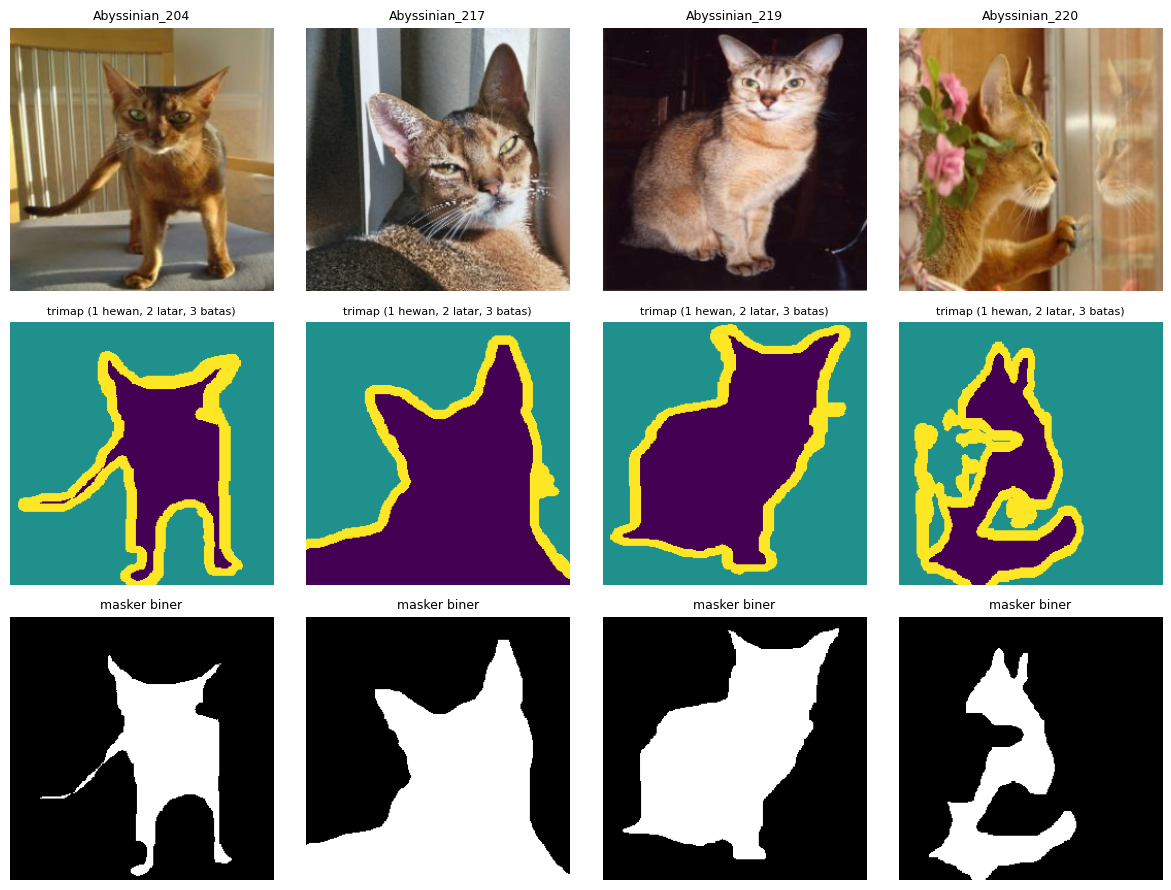

In [ ]:
def denorm(x):
    return (x * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for k in range(4):
    x, y, v = ds_test[k]
    ax[0, k].imshow(denorm(x)); ax[0, k].set_title(ID_TEST[k], fontsize=9)
    ax[1, k].imshow(ds_test.tri[k], cmap="viridis", vmin=1, vmax=3); ax[1, k].set_title("trimap (1 hewan, 2 latar, 3 batas)", fontsize=8)
    ax[2, k].imshow(y[0], cmap="gray"); ax[2, k].set_title("masker biner", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d1_contoh_data.png", dpi=120); plt.show()

### Tugas kecil D1: proporsi piksel pada data uji

In [ ]:
tri_uji = ds_test.tri
for k, nama in [(1, "hewan"), (2, "latar"), (3, "batas")]:
    print(f"Proporsi piksel {nama} (data uji): {(tri_uji == k).float().mean().item():.3f}")

Proporsi piksel hewan (data uji): 0.301
Proporsi piksel latar (data uji): 0.575
Proporsi piksel batas (data uji): 0.124


## Praktikum D2: Membangun dan Melatih U-Net dari Nol

In [ ]:
class DoubleConv(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=16):
        super().__init__()
        c = [base, base*2, base*4, base*8, base*16]
        self.enc = nn.ModuleList([DoubleConv(in_ch, c[0])] + [DoubleConv(c[i], c[i+1]) for i in range(4)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(c[i+1], c[i], 2, stride=2) for i in reversed(range(4))])
        self.dec = nn.ModuleList([DoubleConv(c[i]*2, c[i]) for i in reversed(range(4))])
        self.head = nn.Conv2d(c[0], out_ch, 1)
    def forward(self, x):
        skips = []
        for i, blk in enumerate(self.enc):
            x = blk(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)
        x = skips.pop()
        for up, dec in zip(self.up, self.dec):
            x = up(x)
            x = dec(torch.cat([x, skips.pop()], dim=1))
        return self.head(x)

unet = UNet(base=CFG["BASE_CH"]).to(DEVICE)
print("Jumlah parameter U-Net: %.2f juta" % (sum(p.numel() for p in unet.parameters()) / 1e6))
print("Uji bentuk keluaran:", tuple(unet(torch.zeros(2, 3, CFG["IMG"], CFG["IMG"], device=DEVICE)).shape))

Jumlah parameter U-Net: 7.76 juta
Uji bentuk keluaran: (2, 1, 256, 256)


In [ ]:
def bce_dice_loss(logit, y, valid, w_dice=1.0, eps=1.0):
    bce = F.binary_cross_entropy_with_logits(logit, y, reduction="none")
    bce = (bce * valid).sum() / valid.sum().clamp_min(1)
    p = torch.sigmoid(logit) * valid
    inter = (p * y * valid).sum(dim=(1, 2, 3))
    dice = 1 - (2 * inter + eps) / (p.sum(dim=(1, 2, 3)) + (y * valid).sum(dim=(1, 2, 3)) + eps)
    return bce + w_dice * dice.mean()

def latih(model, forward, epochs, lr, nama, param_groups=None, w_dice=1.0):
    opt = torch.optim.AdamW(param_groups or model.parameters(), lr=lr, weight_decay=1e-4)
    riwayat = {"train": [], "test": []}
    t0 = time.time()
    for ep in range(epochs):
        model.train(); tot = 0
        for x, y, v in dl_train:
            x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
            loss = bce_dice_loss(forward(model, x), y, v, w_dice=w_dice)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(x)
        model.eval(); tot_te = 0
        with torch.no_grad():
            for x, y, v in dl_test:
                x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
                tot_te += bce_dice_loss(forward(model, x), y, v, w_dice=w_dice).item() * len(x)
        riwayat["train"].append(tot / len(ds_train)); riwayat["test"].append(tot_te / len(ds_test))
        print(f"[{nama}] epoch {ep+1}/{epochs} loss latih {riwayat['train'][-1]:.4f} loss uji {riwayat['test'][-1]:.4f} ({time.time()-t0:.0f} s)")
    WAKTU[nama] = time.time() - t0
    return riwayat

fwd_unet = lambda m, x: m(x)
set_seed(42)
hist_unet = latih(unet, fwd_unet, CFG["EP_UNET"], 1e-3, "U-Net (dari nol)")

[U-Net (dari nol)] epoch 1/15 loss latih 0.9006 loss uji 0.8568 (45 s)
[U-Net (dari nol)] epoch 2/15 loss latih 0.7053 loss uji 0.7371 (91 s)
[U-Net (dari nol)] epoch 3/15 loss latih 0.6238 loss uji 0.6220 (137 s)
[U-Net (dari nol)] epoch 4/15 loss latih 0.5488 loss uji 0.5464 (184 s)
[U-Net (dari nol)] epoch 5/15 loss latih 0.5094 loss uji 0.5633 (231 s)
[U-Net (dari nol)] epoch 6/15 loss latih 0.4700 loss uji 0.5062 (278 s)
[U-Net (dari nol)] epoch 7/15 loss latih 0.4364 loss uji 0.4519 (325 s)
[U-Net (dari nol)] epoch 8/15 loss latih 0.4015 loss uji 0.3861 (372 s)
[U-Net (dari nol)] epoch 9/15 loss latih 0.3811 loss uji 0.4140 (418 s)
[U-Net (dari nol)] epoch 10/15 loss latih 0.3589 loss uji 0.3609 (465 s)
[U-Net (dari nol)] epoch 11/15 loss latih 0.3368 loss uji 0.3782 (512 s)
[U-Net (dari nol)] epoch 12/15 loss latih 0.3212 loss uji 0.3441 (560 s)
[U-Net (dari nol)] epoch 13/15 loss latih 0.3074 loss uji 0.3332 (606 s)
[U-Net (dari nol)] epoch 14/15 loss latih 0.2969 loss uji 0.33

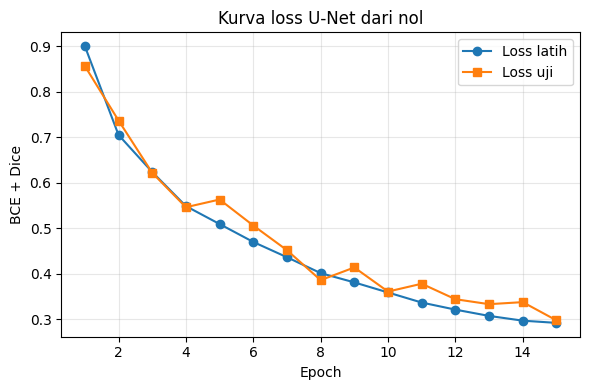

In [ ]:
plt.figure(figsize=(6, 4))
ep = range(1, len(hist_unet["train"]) + 1)
plt.plot(ep, hist_unet["train"], "o-", label="Loss latih")
plt.plot(ep, hist_unet["test"], "s-", label="Loss uji")
plt.xlabel("Epoch"); plt.ylabel("BCE + Dice"); plt.title("Kurva loss U-Net dari nol"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d2_kurva_unet.png", dpi=120); plt.show()

## Praktikum D3: Metrik Evaluasi Segmentasi

In [ ]:
@torch.no_grad()
def evaluasi(model, forward, thr=0.5):
    model.eval()
    TP = FP = FN = TN = 0; iou_per_citra = []
    for x, y, v in dl_test:
        x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
        pred = (torch.sigmoid(forward(model, x)) > thr).float()
        tp = (pred * y * v).sum(dim=(1, 2, 3)); fp = (pred * (1 - y) * v).sum(dim=(1, 2, 3))
        fn = ((1 - pred) * y * v).sum(dim=(1, 2, 3)); tn = ((1 - pred) * (1 - y) * v).sum(dim=(1, 2, 3))
        TP += tp.sum().item(); FP += fp.sum().item(); FN += fn.sum().item(); TN += tn.sum().item()
        iou_per_citra += (tp / (tp + fp + fn).clamp_min(1)).tolist()
    iou_fg = TP / (TP + FP + FN); iou_bg = TN / (TN + FN + FP)
    return {"IoU_hewan": iou_fg, "IoU_latar": iou_bg, "mIoU": (iou_fg + iou_bg) / 2,
            "Dice": 2 * TP / (2 * TP + FP + FN), "PixelAcc": (TP + TN) / (TP + TN + FP + FN),
            "iou_per_citra": iou_per_citra}

def ringkas(m):
    return {k: round(v, 4) for k, v in m.items() if k != "iou_per_citra"}

HASIL = {}
HASIL["U-Net (dari nol)"] = evaluasi(unet, fwd_unet)
print(ringkas(HASIL["U-Net (dari nol)"]))

{'IoU_hewan': 0.8323, 'IoU_latar': 0.9096, 'mIoU': 0.871, 'Dice': 0.9085, 'PixelAcc': 0.9376}


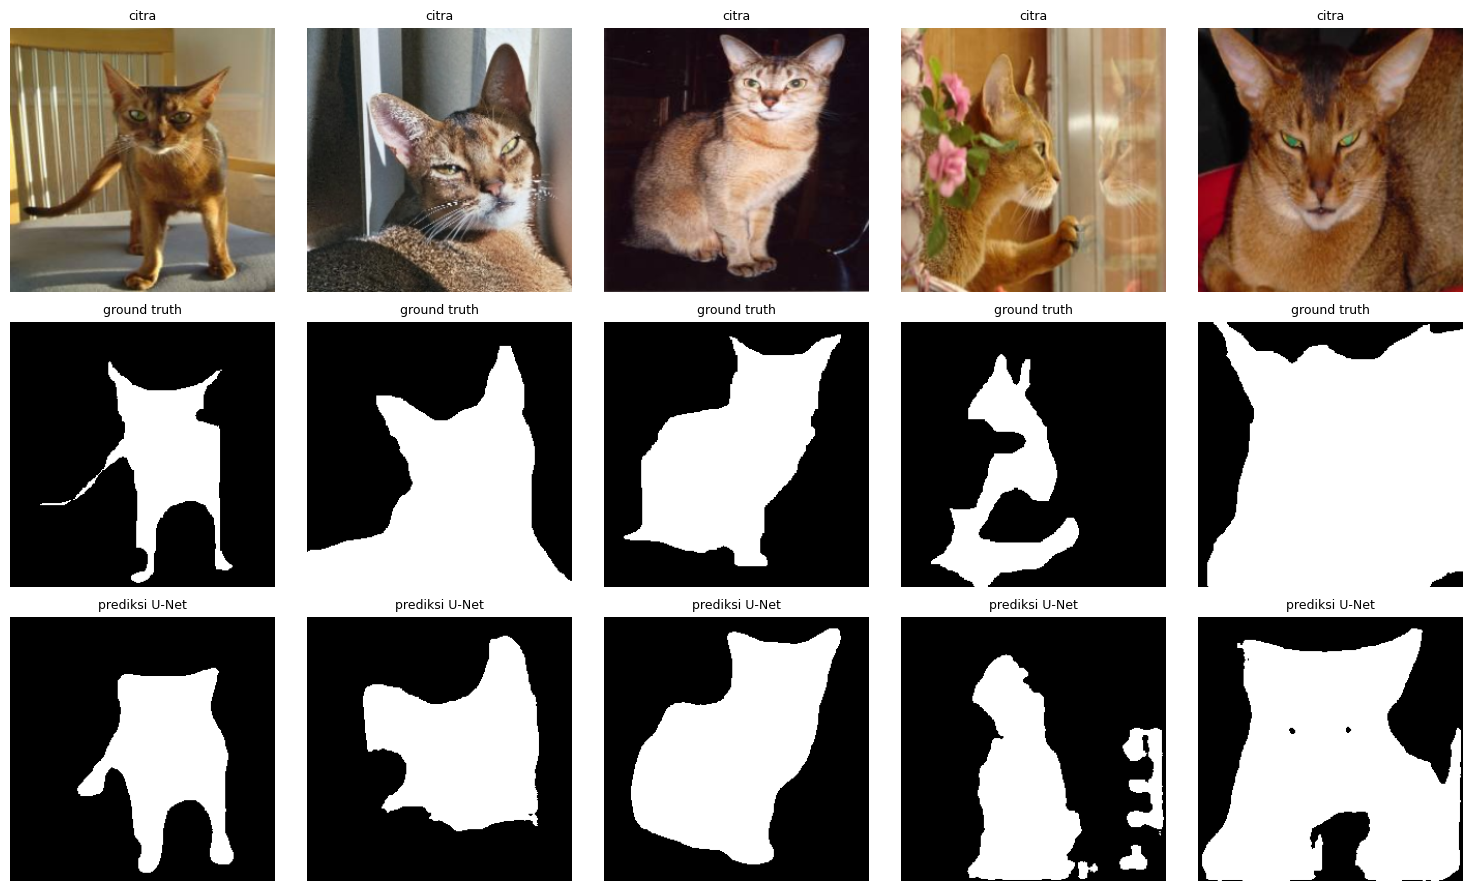

In [ ]:
@torch.no_grad()
def prediksi(model, forward, idx):
    model.eval()
    x = torch.stack([ds_test[i][0] for i in idx]).to(DEVICE)
    return (torch.sigmoid(forward(model, x)) > 0.5).float().cpu()

idx_vis = [0, 1, 2, 3, 4]
p_unet = prediksi(unet, fwd_unet, idx_vis)
fig, ax = plt.subplots(3, len(idx_vis), figsize=(3 * len(idx_vis), 9))
for j, i in enumerate(idx_vis):
    x, y, v = ds_test[i]
    ax[0, j].imshow(denorm(x)); ax[0, j].set_title("citra", fontsize=9)
    ax[1, j].imshow(y[0], cmap="gray"); ax[1, j].set_title("ground truth", fontsize=9)
    ax[2, j].imshow(p_unet[j, 0], cmap="gray"); ax[2, j].set_title("prediksi U-Net", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d3_prediksi_unet.png", dpi=120); plt.show()

### Tugas kecil D3: pengaruh ambang (thr)

In [ ]:
for thr in (0.3, 0.5, 0.7):
    r = evaluasi(unet, fwd_unet, thr=thr)
    print(f"thr={thr} | IoU hewan {r['IoU_hewan']:.4f} | Dice {r['Dice']:.4f} | mIoU {r['mIoU']:.4f} | PixelAcc {r['PixelAcc']:.4f}")

thr=0.3 | IoU hewan 0.8319 | Dice 0.9082 | mIoU 0.8684 | PixelAcc 0.9354
thr=0.5 | IoU hewan 0.8323 | Dice 0.9085 | mIoU 0.8710 | PixelAcc 0.9376
thr=0.7 | IoU hewan 0.8174 | Dice 0.8995 | mIoU 0.8616 | PixelAcc 0.9337


### Tugas kecil D2: hanya BCE (w_dice=0) dibandingkan dengan BCE + Dice

In [ ]:
set_seed(42)
unet_bce = UNet(base=CFG["BASE_CH"]).to(DEVICE)
hist_unet_bce = latih(unet_bce, fwd_unet, CFG["EP_UNET"], 1e-3, "U-Net (BCE saja)", w_dice=0.0)
hasil_bce = evaluasi(unet_bce, fwd_unet)
print("BCE saja   :", ringkas(hasil_bce))
print("BCE + Dice :", ringkas(HASIL["U-Net (dari nol)"]))

[U-Net (BCE saja)] epoch 1/15 loss latih 0.4541 loss uji 0.4662 (47 s)
[U-Net (BCE saja)] epoch 2/15 loss latih 0.3421 loss uji 0.3384 (94 s)
[U-Net (BCE saja)] epoch 3/15 loss latih 0.3162 loss uji 0.4023 (141 s)
[U-Net (BCE saja)] epoch 4/15 loss latih 0.2826 loss uji 0.3279 (187 s)
[U-Net (BCE saja)] epoch 5/15 loss latih 0.2567 loss uji 0.2730 (234 s)
[U-Net (BCE saja)] epoch 6/15 loss latih 0.2418 loss uji 0.2350 (281 s)
[U-Net (BCE saja)] epoch 7/15 loss latih 0.2243 loss uji 0.2324 (328 s)
[U-Net (BCE saja)] epoch 8/15 loss latih 0.2155 loss uji 0.2381 (375 s)
[U-Net (BCE saja)] epoch 9/15 loss latih 0.2039 loss uji 0.2117 (421 s)
[U-Net (BCE saja)] epoch 10/15 loss latih 0.1932 loss uji 0.2011 (468 s)
[U-Net (BCE saja)] epoch 11/15 loss latih 0.1772 loss uji 0.2627 (515 s)
[U-Net (BCE saja)] epoch 12/15 loss latih 0.1745 loss uji 0.1918 (562 s)
[U-Net (BCE saja)] epoch 13/15 loss latih 0.1643 loss uji 0.1739 (609 s)
[U-Net (BCE saja)] epoch 14/15 loss latih 0.1613 loss uji 0.21

## Praktikum D4: Transfer Learning dengan DeepLabV3

In [ ]:
from torchvision.models.segmentation import deeplabv3_mobilenet_v3_large, DeepLabV3_MobileNet_V3_Large_Weights

set_seed(42)
dlv3 = deeplabv3_mobilenet_v3_large(weights=DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT)
dlv3.classifier[4] = nn.Conv2d(256, 1, kernel_size=1)
dlv3.aux_classifier = None
dlv3 = dlv3.to(DEVICE)
print("Jumlah parameter DeepLabV3-MobileNetV3: %.2f juta" % (sum(p.numel() for p in dlv3.parameters()) / 1e6))

fwd_dlv3 = lambda m, x: m(x)["out"]
groups = [{"params": dlv3.backbone.parameters(), "lr": 1e-4},
          {"params": dlv3.classifier.parameters(), "lr": 1e-3}]
hist_dlv3 = latih(dlv3, fwd_dlv3, CFG["EP_DLV3"], 1e-3, "DeepLabV3-MobileNetV3 (pra-latih)", param_groups=groups)
HASIL["DeepLabV3-MobileNetV3 (pra-latih)"] = evaluasi(dlv3, fwd_dlv3)
print(ringkas(HASIL["DeepLabV3-MobileNetV3 (pra-latih)"]))

Downloading: "https://download.pytorch.org/models/deeplabv3_mobilenet_v3_large-fc3c493d.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_mobilenet_v3_large-fc3c493d.pth


100%|██████████| 42.3M/42.3M [00:00<00:00, 168MB/s]


Jumlah parameter DeepLabV3-MobileNetV3: 11.02 juta
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 1/6 loss latih 0.1819 loss uji 0.1295 (22 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 2/6 loss latih 0.0925 loss uji 0.1252 (44 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 3/6 loss latih 0.0719 loss uji 0.1034 (65 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 4/6 loss latih 0.0588 loss uji 0.1063 (86 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 5/6 loss latih 0.0526 loss uji 0.1115 (108 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 6/6 loss latih 0.0448 loss uji 0.1033 (129 s)
{'IoU_hewan': 0.9533, 'IoU_latar': 0.9752, 'mIoU': 0.9643, 'Dice': 0.9761, 'PixelAcc': 0.9835}


### Tugas kecil D4: bekukan backbone

In [ ]:
set_seed(42)
dlv3_beku = deeplabv3_mobilenet_v3_large(weights=DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT)
dlv3_beku.classifier[4] = nn.Conv2d(256, 1, kernel_size=1)
dlv3_beku.aux_classifier = None
dlv3_beku = dlv3_beku.to(DEVICE)
for p in dlv3_beku.backbone.parameters():
    p.requires_grad = False
groups_beku = [{"params": dlv3_beku.classifier.parameters(), "lr": 1e-3}]
hist_beku = latih(dlv3_beku, fwd_dlv3, CFG["EP_DLV3"], 1e-3, "DeepLabV3 (backbone beku)", param_groups=groups_beku)
hasil_beku = evaluasi(dlv3_beku, fwd_dlv3)
print("Backbone beku  :", ringkas(hasil_beku), "| waktu total (s):", round(WAKTU["DeepLabV3 (backbone beku)"], 1))
print("Fine-tune penuh:", ringkas(HASIL["DeepLabV3-MobileNetV3 (pra-latih)"]), "| waktu total (s):", round(WAKTU["DeepLabV3-MobileNetV3 (pra-latih)"], 1))

[DeepLabV3 (backbone beku)] epoch 1/6 loss latih 0.2181 loss uji 0.1420 (13 s)
[DeepLabV3 (backbone beku)] epoch 2/6 loss latih 0.1439 loss uji 0.1515 (25 s)
[DeepLabV3 (backbone beku)] epoch 3/6 loss latih 0.1285 loss uji 0.1395 (38 s)
[DeepLabV3 (backbone beku)] epoch 4/6 loss latih 0.1106 loss uji 0.1388 (51 s)
[DeepLabV3 (backbone beku)] epoch 5/6 loss latih 0.1017 loss uji 0.1396 (63 s)
[DeepLabV3 (backbone beku)] epoch 6/6 loss latih 0.0943 loss uji 0.1516 (76 s)
Backbone beku  : {'IoU_hewan': 0.9262, 'IoU_latar': 0.9602, 'mIoU': 0.9432, 'Dice': 0.9617, 'PixelAcc': 0.9734} | waktu total (s): 75.9
Fine-tune penuh: {'IoU_hewan': 0.9533, 'IoU_latar': 0.9752, 'mIoU': 0.9643, 'Dice': 0.9761, 'PixelAcc': 0.9835} | waktu total (s): 129.2


## Praktikum D5: Fine-Tuning SegFormer-B0

In [ ]:
import transformers
from transformers import SegformerForSemanticSegmentation
transformers.logging.set_verbosity_error()

set_seed(42)
segf = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b0", num_labels=1).to(DEVICE)
print("Jumlah parameter SegFormer-B0: %.2f juta" % (sum(p.numel() for p in segf.parameters()) / 1e6))

def fwd_segf(m, x):
    logit = m(pixel_values=x).logits
    return F.interpolate(logit, size=x.shape[-2:], mode="bilinear", align_corners=False)

hist_segf = latih(segf, fwd_segf, CFG["EP_SEGF"], 3e-4, "SegFormer-B0 (pra-latih)")
HASIL["SegFormer-B0 (pra-latih)"] = evaluasi(segf, fwd_segf)
print(ringkas(HASIL["SegFormer-B0 (pra-latih)"]))

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 14.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Jumlah parameter SegFormer-B0: 3.71 juta


model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

[SegFormer-B0 (pra-latih)] epoch 1/6 loss latih 0.3120 loss uji 0.1501 (28 s)
[SegFormer-B0 (pra-latih)] epoch 2/6 loss latih 0.1528 loss uji 0.1366 (53 s)
[SegFormer-B0 (pra-latih)] epoch 3/6 loss latih 0.1075 loss uji 0.1082 (82 s)
[SegFormer-B0 (pra-latih)] epoch 4/6 loss latih 0.0815 loss uji 0.1229 (107 s)
[SegFormer-B0 (pra-latih)] epoch 5/6 loss latih 0.0736 loss uji 0.1119 (132 s)
[SegFormer-B0 (pra-latih)] epoch 6/6 loss latih 0.0707 loss uji 0.1259 (157 s)
{'IoU_hewan': 0.9389, 'IoU_latar': 0.967, 'mIoU': 0.9529, 'Dice': 0.9685, 'PixelAcc': 0.9781}


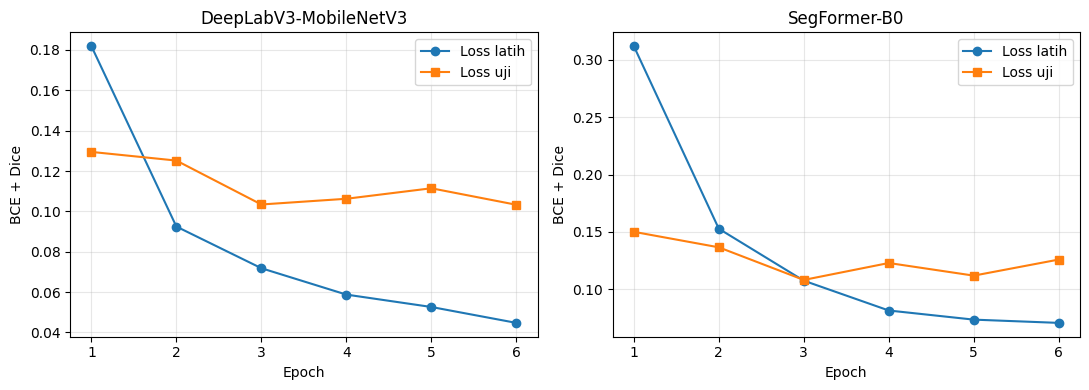

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (nama, h) in zip(ax, [("DeepLabV3-MobileNetV3", hist_dlv3), ("SegFormer-B0", hist_segf)]):
    ep = range(1, len(h["train"]) + 1)
    a.plot(ep, h["train"], "o-", label="Loss latih"); a.plot(ep, h["test"], "s-", label="Loss uji")
    a.set_title(nama); a.set_xlabel("Epoch"); a.set_ylabel("BCE + Dice"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d5_kurva_pralatih.png", dpi=120); plt.show()

### Tugas kecil D5: SegFormer mit-b1

In [ ]:
set_seed(42)
segf_b1 = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b1", num_labels=1).to(DEVICE)
n_b1 = sum(p.numel() for p in segf_b1.parameters()) / 1e6
hist_b1 = latih(segf_b1, fwd_segf, CFG["EP_SEGF"], 3e-4, "SegFormer-B1 (pra-latih)")
hasil_b1 = evaluasi(segf_b1, fwd_segf)
print("Parameter B1: %.2f juta | waktu per epoch: %.1f s" % (n_b1, WAKTU["SegFormer-B1 (pra-latih)"] / CFG["EP_SEGF"]))
print("B1:", ringkas(hasil_b1))
print("B0:", ringkas(HASIL["SegFormer-B0 (pra-latih)"]), "| waktu per epoch: %.1f s" % (WAKTU["SegFormer-B0 (pra-latih)"] / CFG["EP_SEGF"]))
del segf_b1
if DEVICE == "cuda":
    torch.cuda.empty_cache()

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 54.7MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 54.7MB            

model.safetensors: downloading bytes:           |  0.00B            

[SegFormer-B1 (pra-latih)] epoch 1/6 loss latih 0.2894 loss uji 0.2169 (42 s)
[SegFormer-B1 (pra-latih)] epoch 2/6 loss latih 0.1213 loss uji 0.1640 (84 s)
[SegFormer-B1 (pra-latih)] epoch 3/6 loss latih 0.0800 loss uji 0.1088 (125 s)
[SegFormer-B1 (pra-latih)] epoch 4/6 loss latih 0.0682 loss uji 0.1319 (167 s)
[SegFormer-B1 (pra-latih)] epoch 5/6 loss latih 0.0683 loss uji 0.1240 (208 s)
[SegFormer-B1 (pra-latih)] epoch 6/6 loss latih 0.0627 loss uji 0.1065 (250 s)
Parameter B1: 13.68 juta | waktu per epoch: 41.7 s
B1: {'IoU_hewan': 0.9444, 'IoU_latar': 0.9704, 'mIoU': 0.9574, 'Dice': 0.9714, 'PixelAcc': 0.9803}
B0: {'IoU_hewan': 0.9389, 'IoU_latar': 0.967, 'mIoU': 0.9529, 'Dice': 0.9685, 'PixelAcc': 0.9781} | waktu per epoch: 26.2 s


## Praktikum D6: Perbandingan Model dan Analisis Kesalahan

In [ ]:
import pandas as pd

MODELS = {"U-Net (dari nol)": (unet, fwd_unet),
          "DeepLabV3-MobileNetV3 (pra-latih)": (dlv3, fwd_dlv3),
          "SegFormer-B0 (pra-latih)": (segf, fwd_segf)}

tabel = pd.DataFrame([{"Model": k, **ringkas(v),
                       "Parameter (juta)": round(sum(p.numel() for p in MODELS[k][0].parameters()) / 1e6, 2),
                       "Waktu latih (s)": round(WAKTU[k], 1)} for k, v in HASIL.items()])
print(tabel.to_string(index=False))
tabel.to_csv(f"{FIG_DIR}/js05_tabel_hasil.csv", index=False)
with open(f"{FIG_DIR}/js05_hasil.json", "w") as f:
    json.dump({"perangkat": DEVICE, "mode": "CEPAT" if CEPAT else "PENUH", "cfg": CFG,
               "hasil": {k: ringkas(v) for k, v in HASIL.items()}, "waktu_detik": WAKTU}, f, indent=2)

                            Model  IoU_hewan  IoU_latar   mIoU   Dice  PixelAcc  Parameter (juta)  Waktu latih (s)
                 U-Net (dari nol)     0.8323     0.9096 0.8710 0.9085    0.9376              7.76            700.1
DeepLabV3-MobileNetV3 (pra-latih)     0.9533     0.9752 0.9643 0.9761    0.9835             11.02            129.2
         SegFormer-B0 (pra-latih)     0.9389     0.9670 0.9529 0.9685    0.9781              3.71            157.3


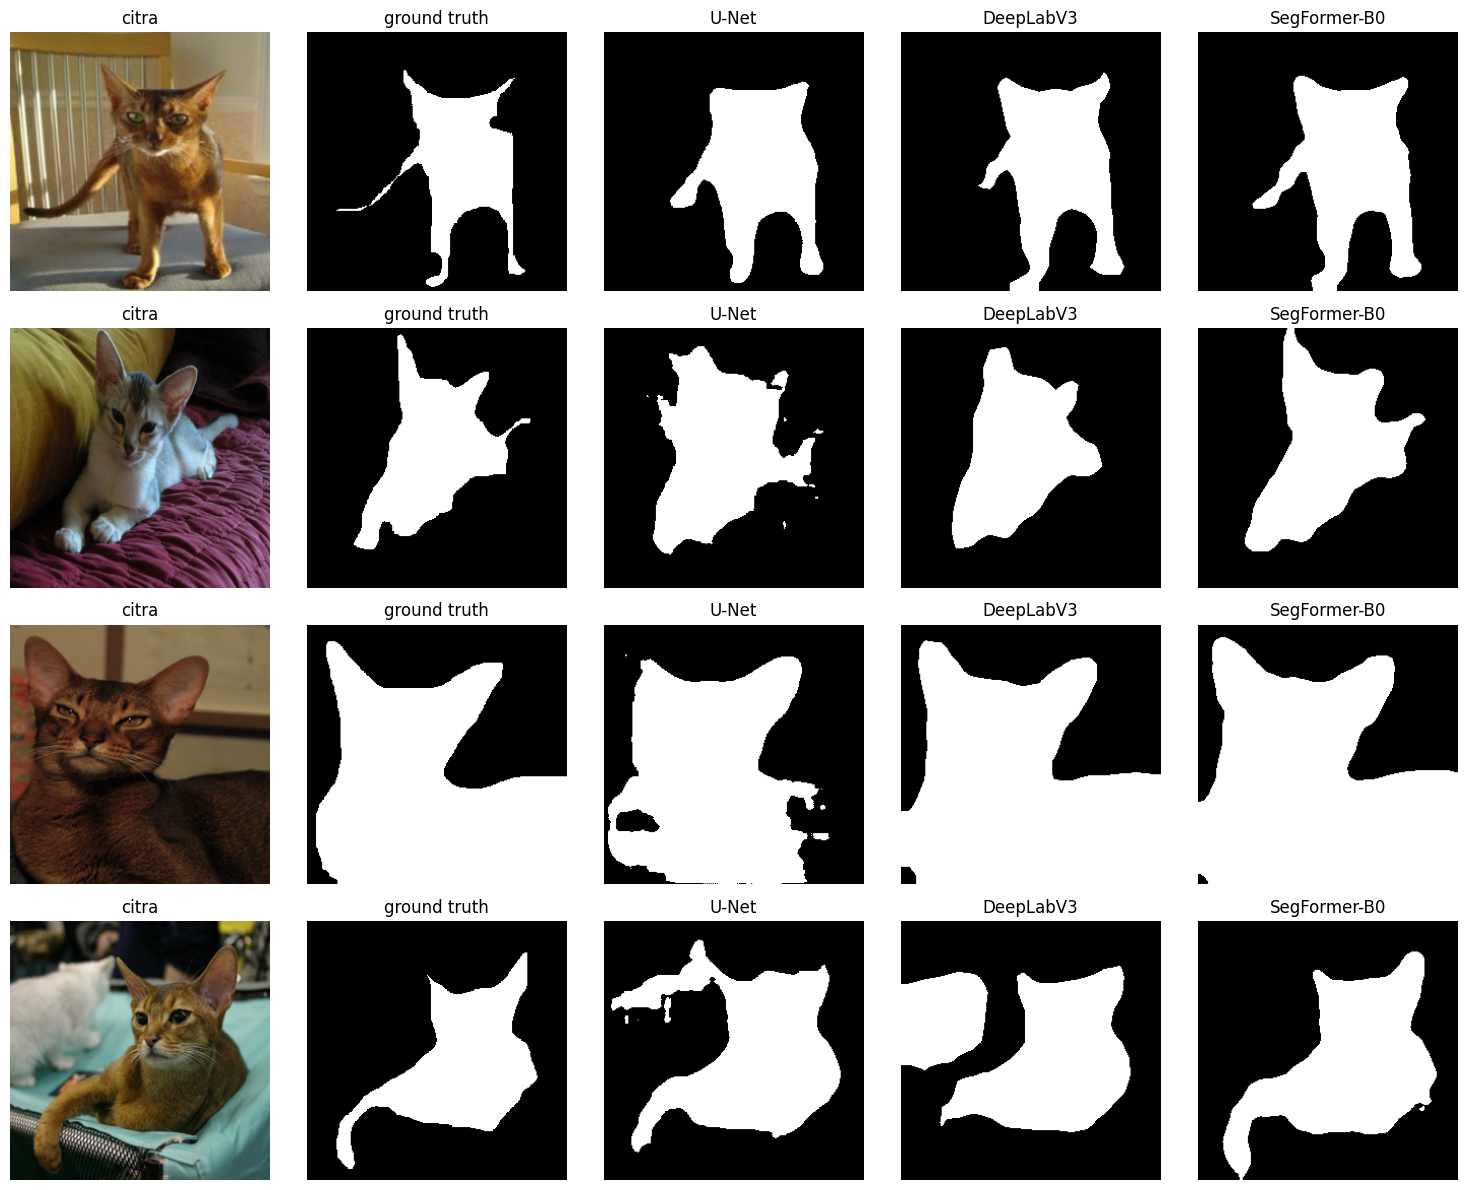

In [ ]:
model_fwd = [("U-Net", unet, fwd_unet), ("DeepLabV3", dlv3, fwd_dlv3), ("SegFormer-B0", segf, fwd_segf)]
idx_vis = [0, 5, 10, 15]
fig, ax = plt.subplots(len(idx_vis), 5, figsize=(15, 3 * len(idx_vis)))
preds = {n: prediksi(m, f, idx_vis) for n, m, f in model_fwd}
for r, i in enumerate(idx_vis):
    x, y, v = ds_test[i]
    ax[r, 0].imshow(denorm(x)); ax[r, 1].imshow(y[0], cmap="gray")
    ax[r, 0].set_title("citra"); ax[r, 1].set_title("ground truth")
    for c, (n, _, _) in enumerate(model_fwd):
        ax[r, c + 2].imshow(preds[n][r, 0], cmap="gray"); ax[r, c + 2].set_title(n)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_perbandingan.png", dpi=110); plt.show()

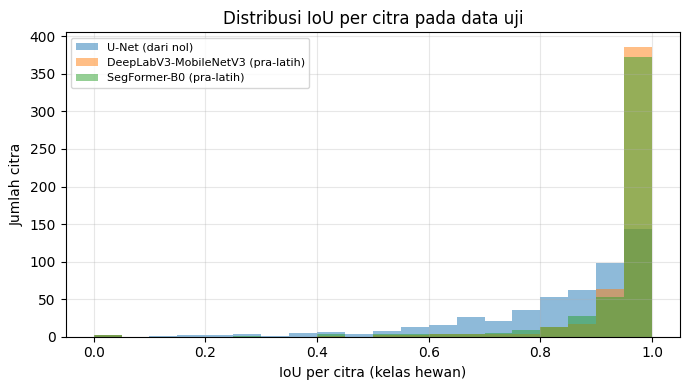

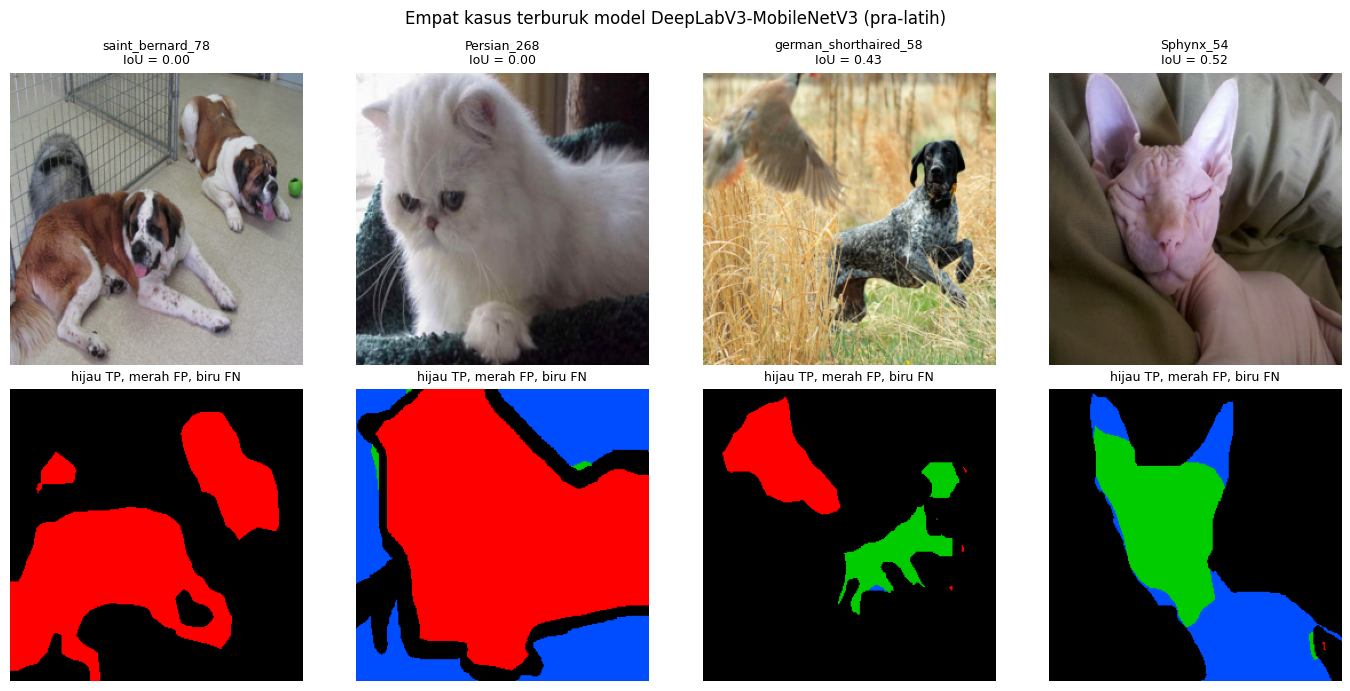

Model terbaik: DeepLabV3-MobileNetV3 (pra-latih) | IoU terendah: [0.0, 0.004, 0.431, 0.515]


In [ ]:
plt.figure(figsize=(7, 4))
for n, m in HASIL.items():
    plt.hist(m["iou_per_citra"], bins=20, range=(0, 1), alpha=.5, label=n)
plt.xlabel("IoU per citra (kelas hewan)"); plt.ylabel("Jumlah citra"); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.title("Distribusi IoU per citra pada data uji")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_histogram_iou.png", dpi=120); plt.show()

terbaik = max(HASIL, key=lambda k: HASIL[k]["mIoU"])
mdl, fw = MODELS[terbaik]
iou = np.array(HASIL[terbaik]["iou_per_citra"]); buruk = np.argsort(iou)[:4].tolist()
pb = prediksi(mdl, fw, buruk)

fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for j, i in enumerate(buruk):
    x, y, v = ds_test[i]; p = pb[j, 0]; g = y[0]; val = v[0]
    peta = np.zeros((*g.shape, 3))
    peta[((p == 1) & (g == 1) & (val == 1)).numpy()] = [0, .8, 0]
    peta[((p == 1) & (g == 0) & (val == 1)).numpy()] = [1, 0, 0]
    peta[((p == 0) & (g == 1) & (val == 1)).numpy()] = [0, .3, 1]
    ax[0, j].imshow(denorm(x)); ax[0, j].set_title(f"{ID_TEST[i]}\nIoU = {iou[i]:.2f}", fontsize=9)
    ax[1, j].imshow(peta); ax[1, j].set_title("hijau TP, merah FP, biru FN", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.suptitle(f"Empat kasus terburuk model {terbaik}")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_kasus_terburuk.png", dpi=110); plt.show()
print("Model terbaik:", terbaik, "| IoU terendah:", np.round(iou[buruk], 3).tolist())

### Tugas kecil D6: tampilkan lebih banyak kasus terburuk (8 kasus) untuk dikelompokkan penyebabnya

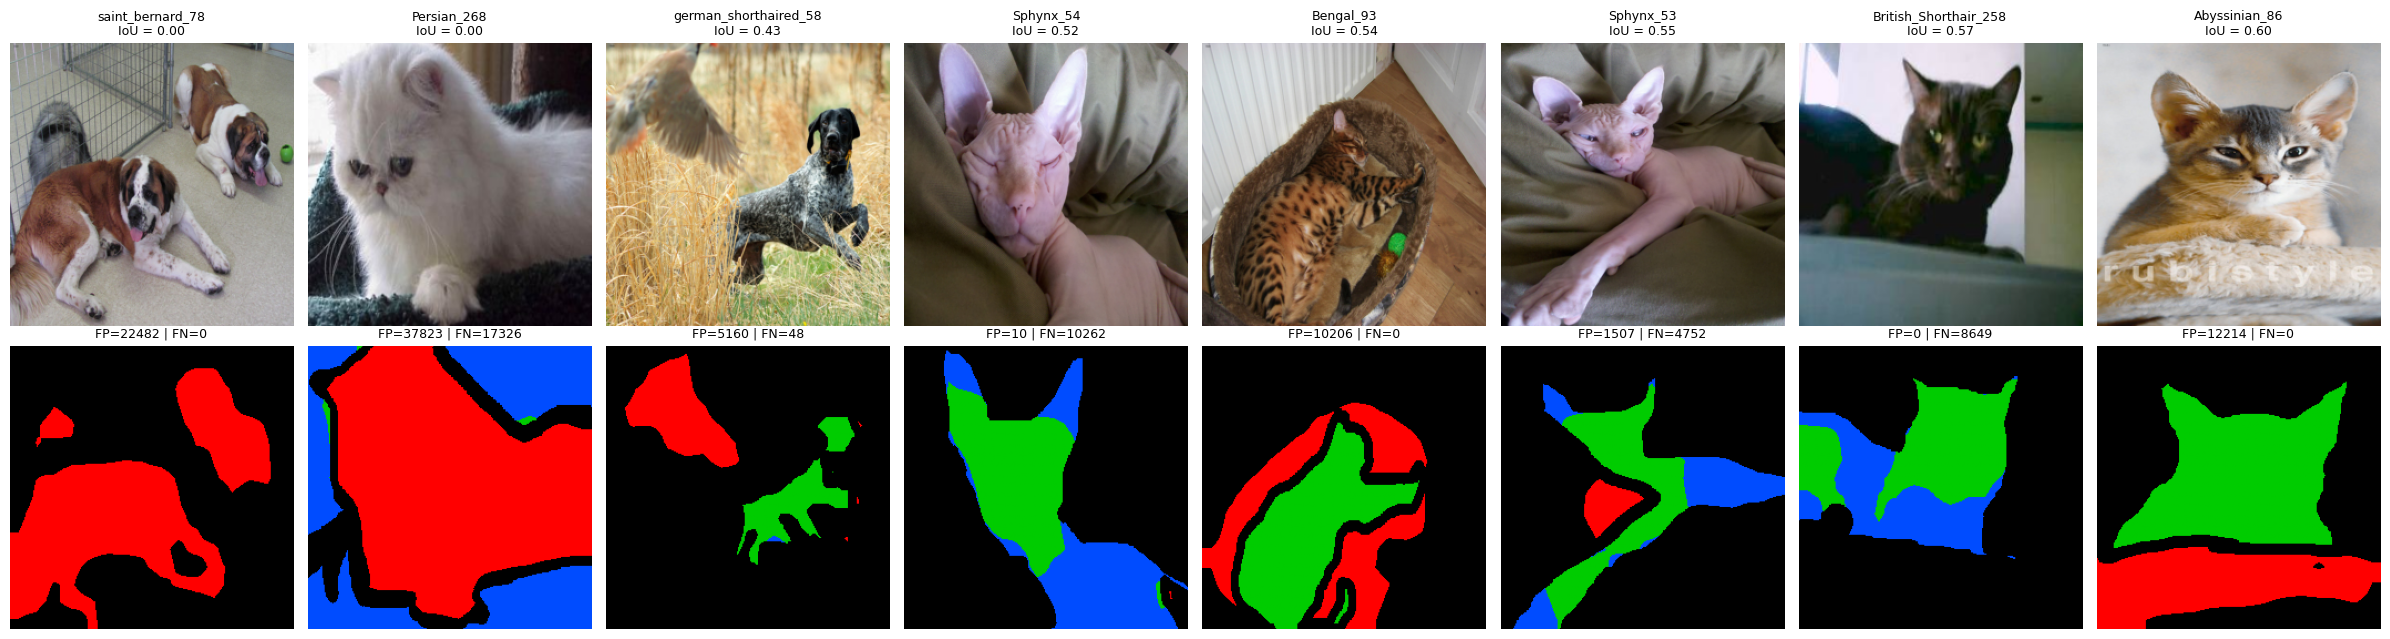

In [ ]:
buruk8 = np.argsort(iou)[:8].tolist()
pb8 = prediksi(mdl, fw, buruk8)
fig, ax = plt.subplots(2, 8, figsize=(24, 6.5))
for j, i in enumerate(buruk8):
    x, y, v = ds_test[i]; p = pb8[j, 0]; g = y[0]; val = v[0]
    peta = np.zeros((*g.shape, 3))
    peta[((p == 1) & (g == 1) & (val == 1)).numpy()] = [0, .8, 0]
    peta[((p == 1) & (g == 0) & (val == 1)).numpy()] = [1, 0, 0]
    peta[((p == 0) & (g == 1) & (val == 1)).numpy()] = [0, .3, 1]
    ax[0, j].imshow(denorm(x)); ax[0, j].set_title(f"{ID_TEST[i]}\nIoU = {iou[i]:.2f}", fontsize=9)
    ax[1, j].imshow(peta)
    fp = ((p == 1) & (g == 0) & (val == 1)).sum().item(); fn = ((p == 0) & (g == 1) & (val == 1)).sum().item()
    ax[1, j].set_title(f"FP={fp} | FN={fn}", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_kasus_terburuk_8.png", dpi=100); plt.show()

# PENUGASAN

### Penugasan 3: bandingkan hasil Anda dengan Tabel 5.5

In [ ]:
acuan = pd.DataFrame([
    {"Model": "U-Net (dari nol)", "IoU_hewan": 0.674, "Dice": 0.805, "PixelAcc": 0.873, "mIoU": 0.751, "Waktu latih (s)": 35},
    {"Model": "DeepLabV3-MobileNetV3 (pra-latih)", "IoU_hewan": 0.836, "Dice": 0.911, "PixelAcc": 0.937, "mIoU": 0.871, "Waktu latih (s)": 15},
    {"Model": "SegFormer-B0 (pra-latih)", "IoU_hewan": 0.867, "Dice": 0.929, "PixelAcc": 0.953, "mIoU": 0.899, "Waktu latih (s)": 19}])
sendiri = tabel[["Model", "IoU_hewan", "Dice", "PixelAcc", "mIoU", "Waktu latih (s)"]]
banding = acuan.merge(sendiri, on="Model", suffixes=(" (Tabel 5.5)", " (milik saya)"))
banding = banding[sorted(banding.columns, key=lambda c: (c != "Model", c))]
print("Perangkat:", DEVICE, "| Mode:", "CEPAT" if CEPAT else "PENUH")
print("Konfigurasi:", CFG)
print(banding.to_string(index=False))

Perangkat: cuda | Mode: PENUH
Konfigurasi: {'IMG': 256, 'N_TRAIN': 2000, 'N_TEST': 500, 'BATCH': 16, 'EP_UNET': 15, 'EP_DLV3': 6, 'EP_SEGF': 6, 'BASE_CH': 32}
                            Model  Dice (Tabel 5.5)  Dice (milik saya)  IoU_hewan (Tabel 5.5)  IoU_hewan (milik saya)  PixelAcc (Tabel 5.5)  PixelAcc (milik saya)  Waktu latih (s) (Tabel 5.5)  Waktu latih (s) (milik saya)  mIoU (Tabel 5.5)  mIoU (milik saya)
                 U-Net (dari nol)             0.805             0.9085                  0.674                  0.8323                 0.873                 0.9376                           35                         700.1             0.751             0.8710
DeepLabV3-MobileNetV3 (pra-latih)             0.911             0.9761                  0.836                  0.9533                 0.937                 0.9835                           15                         129.2             0.871             0.9643
         SegFormer-B0 (pra-latih)             0.929             

### Penugasan 4: eksperimen perbaikan (satu variabel: jumlah epoch SegFormer-B0 digandakan)

In [ ]:
HASIL_EKS = {}
EP_BARU = CFG["EP_SEGF"] * 2
set_seed(42)
segf_eks = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b0", num_labels=1).to(DEVICE)
hist_eks = latih(segf_eks, fwd_segf, EP_BARU, 3e-4, f"SegFormer-B0 ({EP_BARU} epoch)")
HASIL_EKS["SegFormer-B0 (epoch x2)"] = evaluasi(segf_eks, fwd_segf)

pembanding = pd.DataFrame([
    {"Eksperimen": f"Baseline ({CFG['EP_SEGF']} epoch)", **ringkas(HASIL["SegFormer-B0 (pra-latih)"])},
    {"Eksperimen": f"Epoch x2 ({EP_BARU} epoch)", **ringkas(HASIL_EKS["SegFormer-B0 (epoch x2)"])}])
print(pembanding.to_string(index=False))
selisih = HASIL_EKS["SegFormer-B0 (epoch x2)"]["mIoU"] - HASIL["SegFormer-B0 (pra-latih)"]["mIoU"]
print("Perubahan mIoU: %+.4f" % selisih)
pembanding.to_csv(f"{FIG_DIR}/js05_eksperimen.csv", index=False)

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[SegFormer-B0 (12 epoch)] epoch 1/12 loss latih 0.3160 loss uji 0.1556 (24 s)
[SegFormer-B0 (12 epoch)] epoch 2/12 loss latih 0.1605 loss uji 0.1359 (49 s)
[SegFormer-B0 (12 epoch)] epoch 3/12 loss latih 0.0997 loss uji 0.1040 (73 s)
[SegFormer-B0 (12 epoch)] epoch 4/12 loss latih 0.0785 loss uji 0.1122 (98 s)
[SegFormer-B0 (12 epoch)] epoch 5/12 loss latih 0.0707 loss uji 0.1168 (122 s)
[SegFormer-B0 (12 epoch)] epoch 6/12 loss latih 0.0614 loss uji 0.1066 (146 s)
[SegFormer-B0 (12 epoch)] epoch 7/12 loss latih 0.0648 loss uji 0.1087 (171 s)
[SegFormer-B0 (12 epoch)] epoch 8/12 loss latih 0.0713 loss uji 0.1445 (195 s)
[SegFormer-B0 (12 epoch)] epoch 9/12 loss latih 0.0611 loss uji 0.1179 (219 s)
[SegFormer-B0 (12 epoch)] epoch 10/12 loss latih 0.0626 loss uji 0.1120 (244 s)
[SegFormer-B0 (12 epoch)] epoch 11/12 loss latih 0.0517 loss uji 0.1032 (268 s)
[SegFormer-B0 (12 epoch)] epoch 12/12 loss latih 0.0446 loss uji 0.1051 (292 s)
         Eksperimen  IoU_hewan  IoU_latar   mIoU   Di

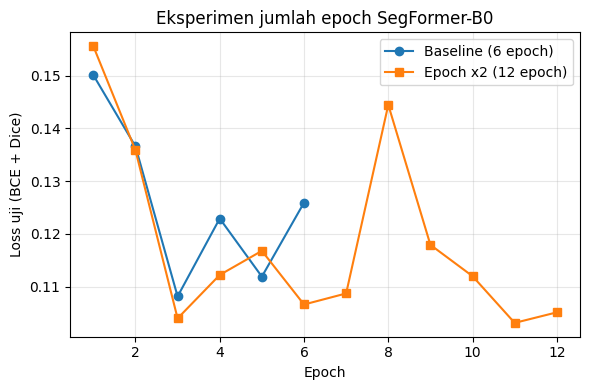

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(hist_segf["test"]) + 1), hist_segf["test"], "o-", label=f"Baseline ({CFG['EP_SEGF']} epoch)")
plt.plot(range(1, len(hist_eks["test"]) + 1), hist_eks["test"], "s-", label=f"Epoch x2 ({EP_BARU} epoch)")
plt.xlabel("Epoch"); plt.ylabel("Loss uji (BCE + Dice)"); plt.title("Eksperimen jumlah epoch SegFormer-B0")
plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_eksperimen_kurva.png", dpi=120); plt.show()

### Penugasan 5: segmentasi foto hewan peliharaan sendiri (minimal 3 foto)

In [ ]:
from google.colab import files
unggah = files.upload()
PATH_FOTO = list(unggah.keys())
print(PATH_FOTO)

Saving 1792138194199.jpg to 1792138194199.jpg
['1792138194199.jpg']


1792138194199.jpg: piksel hewan diprediksi 31.8% dari citra


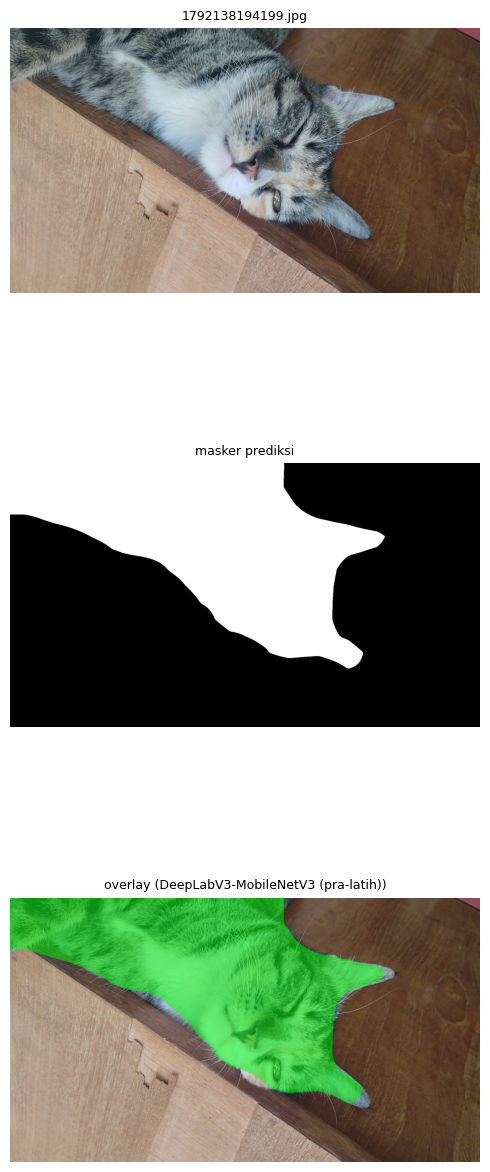

In [ ]:
def segmentasi_foto(path, model, forward, thr=0.5):
    img = Image.open(path).convert("RGB")
    asli = np.array(img)
    kecil = img.resize((CFG["IMG"], CFG["IMG"]), Image.BILINEAR)
    x = torch.from_numpy(np.array(kecil)).permute(2, 0, 1).float() / 255.0
    x = ((x - MEAN) / STD).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        prob = torch.sigmoid(forward(model, x))
        prob = F.interpolate(prob, size=asli.shape[:2], mode="bilinear", align_corners=False)
    return asli, (prob[0, 0] > thr).cpu().numpy()

def overlay(asli, mask, alpha=0.5):
    hasil = asli.astype(np.float32).copy()
    warna = np.array([0, 255, 0], dtype=np.float32)
    hasil[mask] = (1 - alpha) * hasil[mask] + alpha * warna
    return hasil.astype(np.uint8)

n = len(PATH_FOTO)
fig, ax = plt.subplots(3, n, figsize=(5 * n, 14), squeeze=False)
for j, path in enumerate(PATH_FOTO):
    asli, mask = segmentasi_foto(path, mdl, fw)
    ax[0, j].imshow(asli); ax[0, j].set_title(os.path.basename(path), fontsize=9)
    ax[1, j].imshow(mask, cmap="gray"); ax[1, j].set_title("masker prediksi", fontsize=9)
    ax[2, j].imshow(overlay(asli, mask)); ax[2, j].set_title(f"overlay ({terbaik})", fontsize=9)
    print(f"{os.path.basename(path)}: piksel hewan diprediksi {mask.mean()*100:.1f}% dari citra")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_penugasan_foto_sendiri.png", dpi=110); plt.show()

In [ ]:
from google.colab import files
unggah = files.upload()
PATH_FOTO = list(unggah.keys())
print(PATH_FOTO)

Saving 1792138194218.jpg to 1792138194218.jpg
['1792138194218.jpg']


1792138194218.jpg: piksel hewan diprediksi 17.7% dari citra


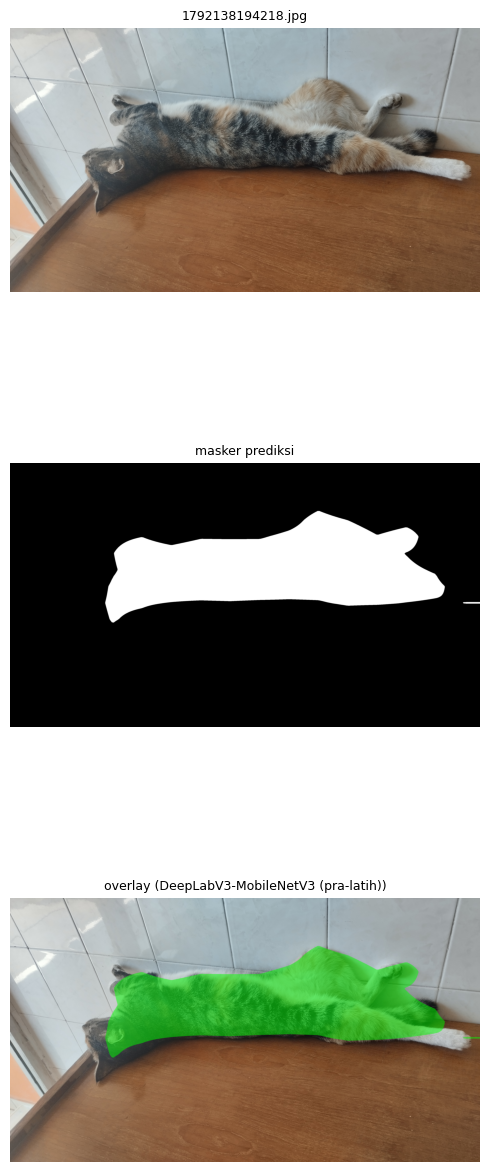

In [ ]:
def segmentasi_foto(path, model, forward, thr=0.5):
    img = Image.open(path).convert("RGB")
    asli = np.array(img)
    kecil = img.resize((CFG["IMG"], CFG["IMG"]), Image.BILINEAR)
    x = torch.from_numpy(np.array(kecil)).permute(2, 0, 1).float() / 255.0
    x = ((x - MEAN) / STD).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        prob = torch.sigmoid(forward(model, x))
        prob = F.interpolate(prob, size=asli.shape[:2], mode="bilinear", align_corners=False)
    return asli, (prob[0, 0] > thr).cpu().numpy()

def overlay(asli, mask, alpha=0.5):
    hasil = asli.astype(np.float32).copy()
    warna = np.array([0, 255, 0], dtype=np.float32)
    hasil[mask] = (1 - alpha) * hasil[mask] + alpha * warna
    return hasil.astype(np.uint8)

n = len(PATH_FOTO)
fig, ax = plt.subplots(3, n, figsize=(5 * n, 14), squeeze=False)
for j, path in enumerate(PATH_FOTO):
    asli, mask = segmentasi_foto(path, mdl, fw)
    ax[0, j].imshow(asli); ax[0, j].set_title(os.path.basename(path), fontsize=9)
    ax[1, j].imshow(mask, cmap="gray"); ax[1, j].set_title("masker prediksi", fontsize=9)
    ax[2, j].imshow(overlay(asli, mask)); ax[2, j].set_title(f"overlay ({terbaik})", fontsize=9)
    print(f"{os.path.basename(path)}: piksel hewan diprediksi {mask.mean()*100:.1f}% dari citra")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_penugasan_foto_sendiri.png", dpi=110); plt.show()

In [ ]:
from google.colab import files
unggah = files.upload()
PATH_FOTO = list(unggah.keys())
print(PATH_FOTO)

Saving 1792138194179.jpg to 1792138194179.jpg
['1792138194179.jpg']


1792138194179.jpg: piksel hewan diprediksi 13.6% dari citra


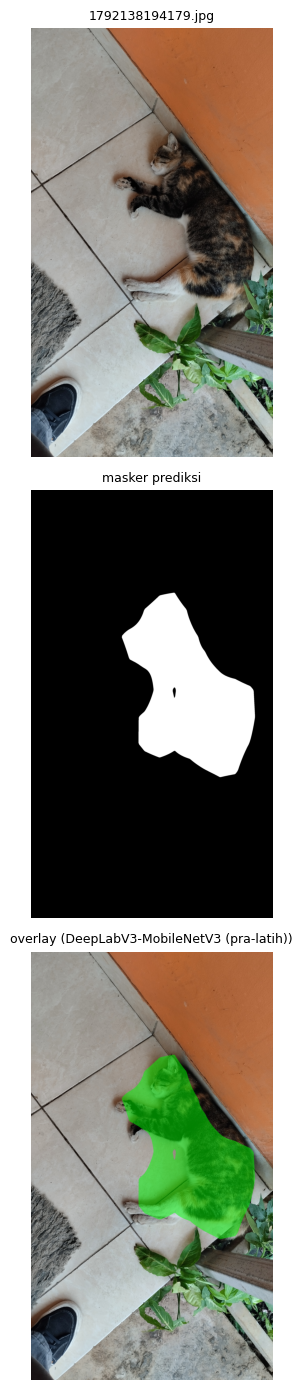

In [ ]:
def segmentasi_foto(path, model, forward, thr=0.5):
    img = Image.open(path).convert("RGB")
    asli = np.array(img)
    kecil = img.resize((CFG["IMG"], CFG["IMG"]), Image.BILINEAR)
    x = torch.from_numpy(np.array(kecil)).permute(2, 0, 1).float() / 255.0
    x = ((x - MEAN) / STD).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        prob = torch.sigmoid(forward(model, x))
        prob = F.interpolate(prob, size=asli.shape[:2], mode="bilinear", align_corners=False)
    return asli, (prob[0, 0] > thr).cpu().numpy()

def overlay(asli, mask, alpha=0.5):
    hasil = asli.astype(np.float32).copy()
    warna = np.array([0, 255, 0], dtype=np.float32)
    hasil[mask] = (1 - alpha) * hasil[mask] + alpha * warna
    return hasil.astype(np.uint8)

n = len(PATH_FOTO)
fig, ax = plt.subplots(3, n, figsize=(5 * n, 14), squeeze=False)
for j, path in enumerate(PATH_FOTO):
    asli, mask = segmentasi_foto(path, mdl, fw)
    ax[0, j].imshow(asli); ax[0, j].set_title(os.path.basename(path), fontsize=9)
    ax[1, j].imshow(mask, cmap="gray"); ax[1, j].set_title("masker prediksi", fontsize=9)
    ax[2, j].imshow(overlay(asli, mask)); ax[2, j].set_title(f"overlay ({terbaik})", fontsize=9)
    print(f"{os.path.basename(path)}: piksel hewan diprediksi {mask.mean()*100:.1f}% dari citra")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_penugasan_foto_sendiri.png", dpi=110); plt.show()